In [1]:
import lenstronomy

import numpy as np
import os
import matplotlib.pyplot as plt

from lenstronomy.LensModel.lens_model import LensModel
from lenstronomy.LightModel.light_model import LightModel


NFW total mass: 8362347149.007823


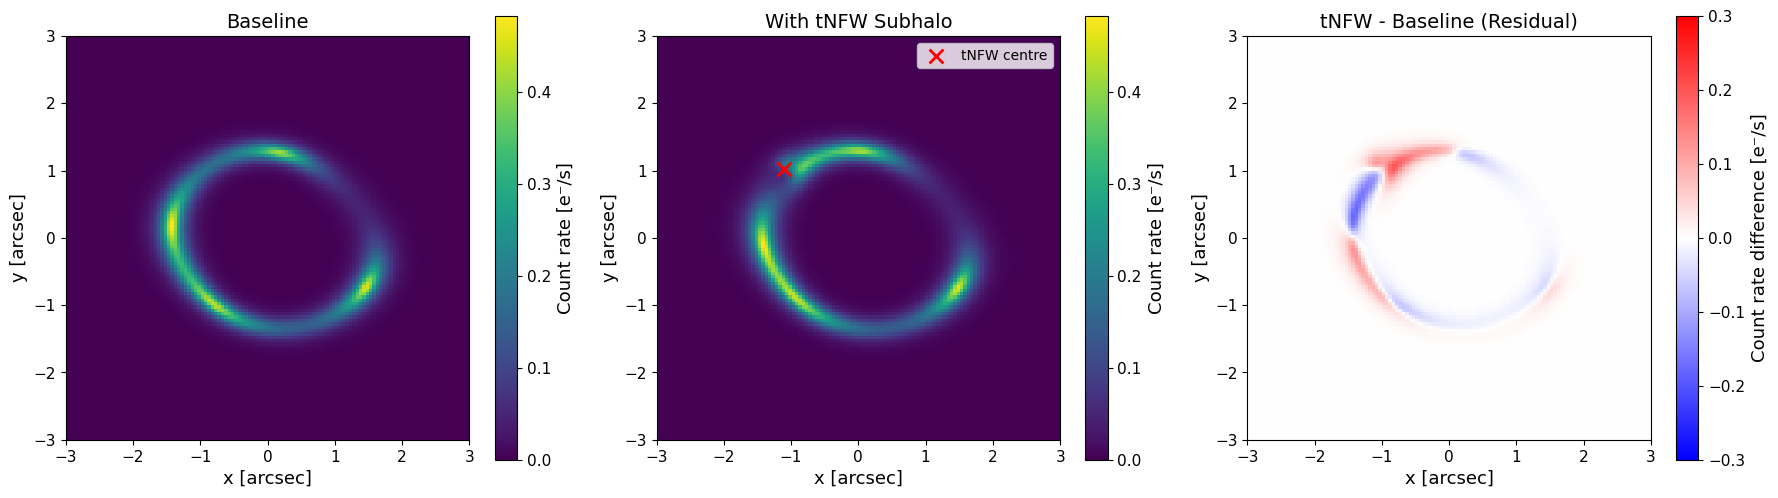

In [12]:

import numpy as np
import matplotlib.pyplot as plt
from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.SimulationAPI.ObservationConfig.HST import HST
from lenstronomy.Util.param_util import (phi_q2_ellipticity, shear_polar2cartesian)


from astropy.cosmology import FlatLambdaCDM
from lenstronomy.Cosmo.lens_cosmo import LensCosmo

# Ballard et al. (2024), Table C1
# Single-plane I-band tNFW model

M200 = 10**10.834
c = 10**1.979 # concentration
r_trunc = 10**(-0.446)  # truncation radius [arcsec]
nfw_x = -1.111         
nfw_y = 1.022  

# redshift of lens and source
z_lens = 0.222
z_source = 0.609

# Cosmology used by Ballard et al.
cosmo = FlatLambdaCDM(H0=67.77, Om0=0.307)

lens_cosmo_nfw = LensCosmo(z_lens=z_lens, z_source=z_source, cosmo=cosmo)


from scipy.integrate import quad

# Calculate the total mass of a truncated NFW halo by integrate truncated density profile from 0 to infinity with the function as a function of M200
def tnfw_total_mass(M200):

    # Calculate NFW scale radius -> this returns angular scale radius of the NFW halo, in arcseconds, and deflection-angle normalization of the NFW halo
    rs_angle, _ = lens_cosmo_nfw.nfw_physical2angle(
        M=M200,
        c=c)

    tau = r_trunc / rs_angle

    f_c = np.log(1 + c) - c / (1 + c)

    # Define the function to integrate
    def integrand(x):
        nfw_term = x / (1 + x)**2
        truncation_term = tau**2 / (x**2 + tau**2)

        return nfw_term * truncation_term


    integral, error = quad(integrand, 0, np.inf)  #quad takes the function integrating, lower limit, upper limit

    return M200 * integral / f_c


M_target = tnfw_total_mass(M200)

print("NFW total mass:", M_target)

# Convert physical mass and concentration into lenstronomy lensing parameters
Rs, alpha_Rs = lens_cosmo_nfw.nfw_physical2angle(M=M200, c=c)

# Use HST-like image properties --> this defines how telescope observes the light
kwargs_single_band = {
    "pixel_scale": 0.05,          # arcsec/pixel
    "exposure_time": 524.0,      # seconds
    "magnitude_zero_point": 25.94,
    "read_noise": 5.25,           
    "ccd_gain": 2.0,             
    "sky_brightness": 22.0,   
    "num_exposures": 4,
    "seeing": 0.10,               # PSF FWHM, arcsec
    "psf_type": "GAUSSIAN"}
# number of pixels on each side of image
numpix = 120



# Objects in model
kwargs_model = {
    "lens_model_list": ["EPL", "SHEAR", "TNFW"],  # foreground galaxy, 
        # EPL describes the main galaxy's gravitational mass distribution. 
        # SHEAR describes a tidal gravitational field produced by other matter in the lens's environment.
        #TNFW is truncated NFW
    "source_light_model_list": ["SERSIC_ELLIPSE"]}   # background galaxy
        # SERSIC_ELLIPSE describes the background galaxy's light distribution


# Create simulation
sim = SimAPI(numpix=numpix, kwargs_single_band=kwargs_single_band, kwargs_model=kwargs_model)
    # SimAPI assembles the telescope and model configurations

image_model = sim.image_model_class(kwargs_numerics={"supersampling_factor": 3})
    # image_model_class() constructs the model responsible for generating the lensed image


# Foreground galaxy parameters

# Ballard et al. (2024), Table C1:
# smooth, single-plane, I-band model

theta_E = 1.397  # Einstein radius [arcsec]
gamma = 2.123   # 3D density slope

q = 0.960     # minor / major axis ratio -> q=b/a
phi = np.deg2rad(-70.113) # orientation of the ellipse, measured counterclockwise from the positive x-axis, in radians

# Convert axis ratio and angle to ellipticity components
e1, e2 = phi_q2_ellipticity(phi, q)

# External shear
shear_strength = 0.107
shear_angle = np.deg2rad(-23.243)

gamma1, gamma2 = shear_polar2cartesian(shear_angle, shear_strength)

kwargs_lens = [
    {"theta_E": theta_E,
     "gamma": gamma,
     "e1": e1,
     "e2": e2,
     "center_x": 0.031,
     "center_y": 0.047},
    {"gamma1": gamma1,
     "gamma2": gamma2}]


# Background galaxy parameters
kwargs_source_mag = [{
    "magnitude": 22.76,
    "R_sersic": 0.18,
    "n_sersic": 1,
    "e1": 0.15,
    "e2": 0.05,
    # slightly offset the source from perfect alignment
    "center_x": 0.08,
    "center_y": -0.03}]



# tNFW

kwargs_nfw = {
    "Rs": Rs,
    "alpha_Rs": alpha_Rs,
    "r_trunc": r_trunc,
    "center_x": nfw_x,
    "center_y": nfw_y}


# EPL + shear + tNFW
kwargs_lens_nfw = [
    kwargs_lens[0],
    kwargs_lens[1],
    kwargs_nfw]

# No halo
kwargs_nfw_off = {
    "Rs": Rs,
    "alpha_Rs": 0.0,
    "r_trunc": r_trunc,
    "center_x": nfw_x,
    "center_y": nfw_y}

_, kwargs_source, _ = sim.magnitude2amplitude(kwargs_source_mag=kwargs_source_mag)
    # converts the source brightness to the units required by lenstronomy

image_baseline = image_model.image(
    kwargs_lens=[
        kwargs_lens[0],
        kwargs_lens[1],
        kwargs_nfw_off],
    kwargs_source=kwargs_source)

# With tNFW halo
image_with_nfw = image_model.image(
    kwargs_lens=kwargs_lens_nfw,
    kwargs_source=kwargs_source)

# Residual
image_difference_nfw = image_with_nfw - image_baseline


pixel_scale = kwargs_single_band["pixel_scale"]
image_size = numpix * pixel_scale


# Plot

pixel_scale = kwargs_single_band["pixel_scale"]
image_size = numpix * pixel_scale

extent = [
    -image_size / 2,
     image_size / 2,
    -image_size / 2,
     image_size / 2]

image_difference_nfw = image_with_nfw - image_baseline

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im1 = axes[0].imshow(
    image_baseline,
    origin="lower",
    extent=extent,
    cmap="viridis",
    vmin=0,
    vmax=max(image_baseline.max(), image_with_nfw.max()))

axes[0].set_title("Baseline", fontsize=14)
axes[0].set_xlabel("x [arcsec]", fontsize=13)
axes[0].set_ylabel("y [arcsec]", fontsize=13)
cbar = fig.colorbar(im1, ax=axes[0])
cbar.set_label("Count rate [e⁻/s]", fontsize=13)
cbar.ax.tick_params(labelsize=11)
axes[0].tick_params(axis="both", labelsize=11)

im2 = axes[1].imshow(
    image_with_nfw,
    origin="lower",
    extent=extent,
    cmap="viridis",
    vmin=0,
    vmax=max(image_baseline.max(), image_with_nfw.max()))

axes[1].set_title("With tNFW Subhalo", fontsize=14)
axes[1].set_xlabel("x [arcsec]", fontsize=13)
axes[1].set_ylabel("y [arcsec]", fontsize=13)
cbar2 = fig.colorbar(im2, ax=axes[1])
cbar2.set_label("Count rate [e⁻/s]", fontsize=13)
cbar2.ax.tick_params(labelsize=11)
axes[1].tick_params(axis="both", labelsize=11)

# Same flux scale for baseline and NFW
flux_max = max(image_baseline.max(), image_with_nfw.max())
residual_max = np.max(np.abs(image_difference_nfw))

im3 = axes[2].imshow(
    image_difference_nfw,
    origin="lower",
    extent=extent,
    cmap="bwr",
    vmin=-0.3,
    vmax=0.3)

axes[1].scatter(nfw_x, nfw_y, color="red", marker="x", s=100,linewidths=2, label="tNFW centre")

axes[1].legend()


axes[2].set_title("tNFW - Baseline (Residual)", fontsize=14)
axes[2].set_xlabel("x [arcsec]", fontsize=13)
axes[2].set_ylabel("y [arcsec]", fontsize=13)
cbar3 = fig.colorbar(im3, ax=axes[2])
cbar3.set_label("Count rate difference [e⁻/s]", fontsize=13)
cbar3.ax.tick_params(labelsize=11)
axes[2].tick_params(axis="both", labelsize=11)

plt.tight_layout()
plt.savefig("nfw_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


In [3]:
rms = np.sqrt(np.mean(image_difference_nfw**2))
max_difference = np.max(np.abs(image_difference_nfw))

print("Residual RMS:", rms)
print("Maximum flux difference:", max_difference)

Residual RMS: 0.016942107497408876
Maximum flux difference: 0.19778627834523133


Relative RMS (1 vs 2): 0.006295689168259872
Relative RMS (2 vs 3): 0.0013096141346494302
Relative RMS (3 vs 4): 0.00040283784151522953
Relative RMS (4 vs 5): 0.0002223323276908887


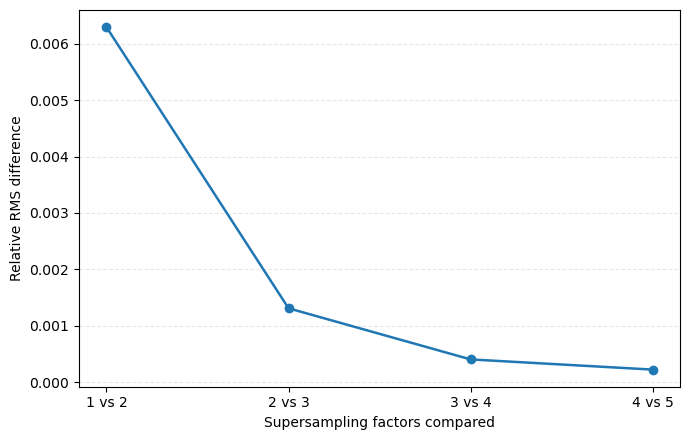

In [4]:

# TEST 4: Numerical convergence

def make_image(supersampling):
    model = sim.image_model_class(kwargs_numerics={"supersampling_factor": supersampling})
    # sim.image_model_class() creates an image-model object using your existing simulation configuration
    # kwargs_numerics is a dictionary containing the numerical settings
    return model.image(kwargs_lens=kwargs_lens_nfw, kwargs_source=kwargs_source)

image_1 = make_image(1)
image_2 = make_image(2)
image_3 = make_image(3)
image_4 = make_image(4)
image_5 = make_image(5)

def relative_rms(a, b):
    return np.sqrt(np.mean((a-b)**2)) / np.sqrt(
        np.mean(b**2))

error_12 = relative_rms(image_1, image_2)
error_23 = relative_rms(image_2, image_3)
error_34 = relative_rms(image_3, image_4)
error_45 = relative_rms(image_4, image_5)

print("Relative RMS (1 vs 2):", error_12)
print("Relative RMS (2 vs 3):", error_23)
print("Relative RMS (3 vs 4):", error_34)
print("Relative RMS (4 vs 5):", error_45)


comparisons = ["1 vs 2", "2 vs 3", "3 vs 4", "4 vs 5"]
errors = [error_12, error_23, error_34, error_45]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(comparisons, errors, marker="o", linewidth=1.8, markersize=6)

ax.set_xlabel("Supersampling factors compared")
ax.set_ylabel("Relative RMS difference")

# ax.set_ylim(0, 0.01)
# ax.set_yticks(np.arange(0, 0.0101, 0.0025))

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("supersampling_convergence.png", dpi=300, bbox_inches="tight")
plt.show()


In [5]:
# TEST 5: tNFW residual convergence

def make_residual(supersampling):
    model = sim.image_model_class(
        kwargs_numerics={"supersampling_factor": supersampling})

    # Without NFW halo
    kwargs_baseline = [
        kwargs_lens[0],
        kwargs_lens[1],
        kwargs_nfw_off]

    baseline = model.image(
        kwargs_lens=kwargs_baseline,
        kwargs_source=kwargs_source)

    # With NFW halo
    with_nfw = model.image(
        kwargs_lens=kwargs_lens_nfw,
        kwargs_source=kwargs_source)

    return with_nfw - baseline


residual_3 = make_residual(3)
residual_5 = make_residual(5)
residual_7 = make_residual(7)

print("Relative RMS (3 vs 5):", relative_rms(residual_3, residual_5))
print("Relative RMS (5 vs 7):", relative_rms(residual_5, residual_7))

Relative RMS (3 vs 5): 0.0012620404023073676
Relative RMS (5 vs 7): 0.0003701720168681844
